# Abstract

This study compares logistic regression, random forest, and histogram gradient boosting on 569 records from the UCI Wisconsin Diagnostic Breast Cancer dataset. Stratified partitions separate training, sigmoid calibration, threshold decisions, and a final test of 86 records. Each model receives three candidates and the same five training folds; development average precision selects Logistic. IDs are excluded, and all preprocessing is fitted within the relevant training partition.

For the selected calibrated model, test ROC AUC is 0.999, average precision is 0.998, Brier score is 0.0248, and five-bin expected calibration error is 0.0318. Its uncalibrated Brier score is 0.0209. Paired stratified bootstrap intervals retain identical sampled test rows across models and probability versions. A sharpened-probability counterexample leaves ranking unchanged while altering probability quality, showing why discrimination alone is insufficient.

A separate decision partition chooses threshold 0.9997 under a hypothetical false-negative cost of five, false-positive cost of one, and thirty-percent review capacity. The threshold plus capacity cap reviews 21 test cases, with 11 false negatives and 0 false positives. Cost and capacity sensitivity, calibration-bin counts, and training-defined radius slices are retained. These are teaching policies, not clinical recommendations. Small calibration, decision, and test samples limit precision, and the bootstrap conditions on fitted models and fixed class counts rather than accounting for training uncertainty or institutional shift.


# DS-A4: Model Comparison and Calibration Lab

**Author:** xuhongbo · **Student ID:** 202618018629048

Compare probability quality and a hypothetical review policy using the UCI Wisconsin Diagnostic Breast Cancer data. Source: https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic, Wolberg, Mangasarian, Street and Street (1993), DOI 10.24432/C5DW2B, CC BY 4.0. This is a statistical teaching exercise on existing anonymized numeric records, not a clinical decision system.

## 01 · Frozen protocol and provenance

Verify the raw-file hashes before analysis. Every run creates a new directory and records its environment. No automatic execution is represented as student independent verification.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, datetime, subprocess, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)
plt.rcParams.update({'figure.dpi':110, 'font.size':10, 'axes.spines.top':False, 'axes.spines.right':False})
BASE = Path.cwd()
assert (BASE / 'protocol.json').exists(), 'Run with this assignment as working directory.'
protocol = json.loads((BASE / 'protocol.json').read_text())
def notebook_code_hash():
    saved=json.loads((BASE/f"A{protocol['assignment']}.ipynb").read_text())
    code=''.join(''.join(c['source']) for c in saved['cells'] if c['cell_type']=='code')
    return hashlib.sha256(code.encode()).hexdigest()
SEED = protocol['seed']
rng = np.random.default_rng(SEED)
RUN = BASE / 'results' / datetime.datetime.now(datetime.timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
RUN.mkdir(parents=True)
(RUN/'figures').mkdir()
def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def save_json(name, value):
    (RUN/name).write_text(json.dumps(value, indent=2, default=lambda x: x.item() if hasattr(x,'item') else str(x))+'\n')
def table(name, value):
    value.to_csv(RUN/(name+'.csv'), index=False)
    display(value.head(20))
def figure(name):
    plt.tight_layout(); plt.savefig(RUN/'figures'/(name+'.png'), dpi=150, bbox_inches='tight'); plt.show(); plt.close()
manifest = json.loads((BASE/'data/raw/manifest.json').read_text())
for filename, expected in manifest['files'].items():
    assert sha(BASE/'data/raw'/filename)==expected, filename
save_json('run_metadata.json', {'started_utc':datetime.datetime.now(datetime.timezone.utc).isoformat(), 'python':sys.version,'executable':sys.executable,'platform':platform.platform(),'protocol_sha256':sha(BASE/'protocol.json'),'manifest_sha256':sha(BASE/'data/raw/manifest.json'),'seed':SEED,'analysis_source_sha256':sha(BASE/'analysis.py'),'notebook_code_sha256':notebook_code_hash()})
(RUN/'protocol.json').write_bytes((BASE/'protocol.json').read_bytes())
(RUN/'requirements-lock.txt').write_text(subprocess.check_output([sys.executable,'-m','pip','freeze'],text=True))
print('Verified raw hashes:', len(manifest['files']))
print('Run:', RUN.name)


Verified raw hashes: 3
Run: 20261010T104325122644Z


## 02 · Disjoint roles and paired model search

Malignancy is the positive label in this historical diagnostic-image dataset. The split reserves separate data for fitting, sigmoid calibration, policy choice and final evaluation. IDs are excluded. The three families receive the same five stratified training folds and three hyperparameter candidates each (15 fits per family), with average precision (AP) as the selection metric. This equal fit-count budget is not equal computational cost. Logistic regression is the strong simple baseline; tree ensembles are alternatives, not presumed improvements.

In [2]:

from sklearn.model_selection import train_test_split,StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,HistGradientBoostingClassifier
from sklearn.base import clone
from sklearn.metrics import average_precision_score,roc_auc_score,brier_score_loss,log_loss,roc_curve,precision_recall_curve
from sklearn.calibration import calibration_curve
from scipy.special import expit,logit
import time
raw=pd.read_csv(BASE/'data/raw/wdbc.data',header=None)
base_names=['radius','texture','perimeter','area','smoothness','compactness','concavity','concave_points','symmetry','fractal_dimension']
names=[f'{n}_{suffix}' for suffix in ['mean','se','worst'] for n in base_names]
X=raw.iloc[:,2:].copy(); X.columns=names; y=(raw.iloc[:,1]=='M').to_numpy().astype(int); ids=raw.iloc[:,0].to_numpy()
all_idx=np.arange(len(y)); rest,test=train_test_split(all_idx,test_size=.15,stratify=y,random_state=SEED)
train,aux=train_test_split(rest,test_size=.25/.85,stratify=y[rest],random_state=SEED+1)
cal,decision=train_test_split(aux,test_size=.4,stratify=y[aux],random_state=SEED+2)
parts={'train':train,'calibration':cal,'decision':decision,'test':test}
assert len(np.unique(np.concatenate(list(parts.values()))))==len(y)
assert len(np.unique(ids))==len(ids)
assert not X.duplicated().any(), 'Audit cross-partition exact duplicates before proceeding.'
split=pd.DataFrame({'row':all_idx,'record_id':ids,'partition':'','fold':-1})
for name,ix in parts.items(): split.loc[ix,'partition']=name
folds=list(StratifiedKFold(5,shuffle=True,random_state=SEED).split(train,y[train]))
for k,(_,iv) in enumerate(folds): split.loc[train[iv],'fold']=k
split.to_csv(RUN/'split.csv',index=False)
candidates={'Logistic':[make_pipeline(SimpleImputer(),StandardScaler(),LogisticRegression(C=c,max_iter=3000,random_state=SEED)) for c in [.1,1,10]],'RandomForest':[make_pipeline(SimpleImputer(),RandomForestClassifier(n_estimators=100,max_depth=d,min_samples_leaf=3,random_state=SEED,n_jobs=1)) for d in [3,6,None]],'HistBoost':[make_pipeline(SimpleImputer(),HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=l,l2_regularization=1,random_state=SEED)) for l in [3,7,15]]}
cv=[]; oof=[]
for name,models in candidates.items():
    for candidate,model in enumerate(models):
        for k,(it,iv) in enumerate(folds):
            start=time.perf_counter(); f=clone(model).fit(X.iloc[train[it]],y[train[it]]); p=f.predict_proba(X.iloc[train[iv]])[:,1]
            cv.append({'model':name,'candidate':candidate,'fold':k,'AP':average_precision_score(y[train[iv]],p),'seconds':time.perf_counter()-start})
            oof.extend({'row':int(row),'fold':k,'model':name,'candidate':candidate,'y':int(y[row]),'p':float(v)} for row,v in zip(train[iv],p))
cv=pd.DataFrame(cv); cv.to_csv(RUN/'cv_scores.csv',index=False); pd.DataFrame(oof).to_csv(RUN/'cv_predictions_all.csv',index=False)
best=cv.groupby(['model','candidate'],as_index=False).AP.mean().sort_values(['AP','model','candidate'],ascending=[False,True,True]).groupby('model',sort=False).head(1)
selected=best.iloc[0].model
save_json('locked_models.json',{'selected':selected,'candidates':best.to_dict('records'),'budget':'3 candidates x 5 identical folds per family; AP objective; wall time recorded'})
print('Partition sizes:',{n:len(ix) for n,ix in parts.items()}); table('selected_cv_models',best)


Partition sizes: {'train': 340, 'calibration': 85, 'decision': 58, 'test': 86}


,model,candidate,AP
4,Logistic,1,0.990471
0,HistBoost,0,0.985732
8,RandomForest,2,0.983139


## 03 · Calibration without reuse of policy/test data

Each selected candidate is fitted on training rows, then a sigmoid maps its log-odds to probabilities using the calibration rows alone. The sigmoid is implemented by a near-unpenalized one-variable logistic model; it is not chosen from several calibration methods. No training or calibration refit uses the policy or test partitions. Calibration can worsen a small-sample estimate; both raw and calibrated probabilities are retained.

,model,version,AP,ROC_AUC,Brier,ECE_5,LogLoss
0,Logistic,raw,0.998076,0.998843,0.020927,0.040409,0.073336
1,Logistic,calibrated,0.998076,0.998843,0.024833,0.031810,0.076576
2,HistBoost,raw,1.000000,1.000000,0.027859,0.052684,0.089461
3,HistBoost,calibrated,1.000000,1.000000,0.019850,0.032036,0.061544
4,RandomForest,raw,0.996027,0.997685,0.026544,0.060902,0.106709
5,RandomForest,calibrated,0.996027,0.997685,0.013551,0.015459,0.108491


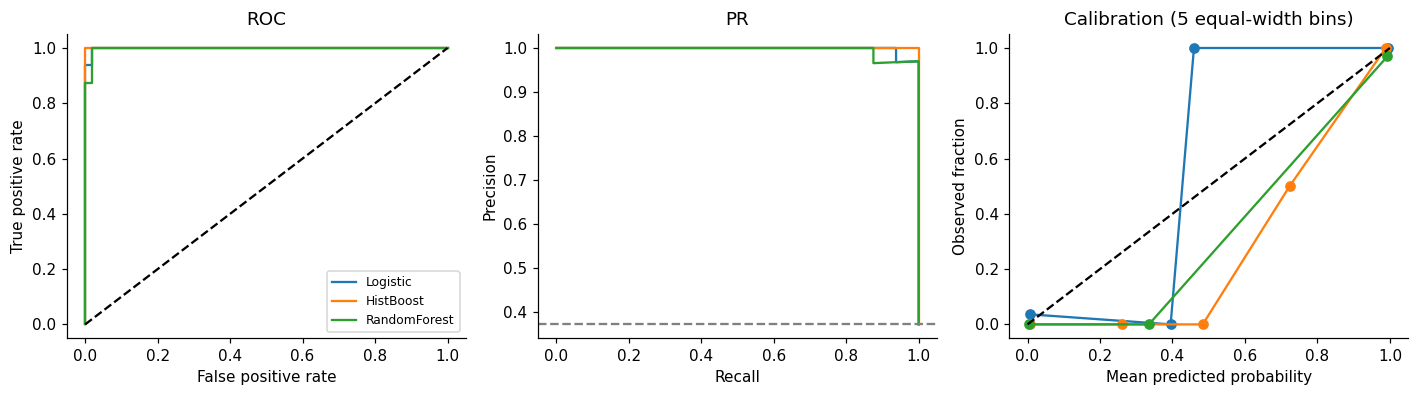

In [3]:

fits={}; calibrators={}; probabilities={}; paired=[]
def lp(p): return logit(np.clip(p,1e-6,1-1e-6)).reshape(-1,1)
for r in best.itertuples():
    name=r.model; fit=clone(candidates[name][r.candidate]).fit(X.iloc[train],y[train]); fits[name]=fit
    pc=fit.predict_proba(X.iloc[cal])[:,1]; sigmoid=LogisticRegression(C=1e6,max_iter=3000).fit(lp(pc),y[cal]); calibrators[name]=sigmoid
    probabilities[name]={}
    for part,ix in [('decision',decision),('test',test)]:
        rawp=fit.predict_proba(X.iloc[ix])[:,1]; calibrated=sigmoid.predict_proba(lp(rawp))[:,1]; probabilities[name][part]=(rawp,calibrated)
        paired.extend({'row':int(row),'partition':part,'y':int(y[row]),'model':name,'raw':float(pr),'calibrated':float(p)} for row,pr,p in zip(ix,rawp,calibrated))
pd.DataFrame(paired).to_csv(RUN/'paired_predictions.csv',index=False)
save_json('sigmoid_parameters.json',{n:{'intercept':float(c.intercept_[0]),'slope':float(c.coef_[0,0])} for n,c in calibrators.items()})
def ece(y,p):
    bins=np.minimum((np.asarray(p)*5).astype(int),4)
    return sum(np.mean(bins==b)*abs(np.mean(y[bins==b])-np.mean(p[bins==b])) for b in range(5) if np.any(bins==b))
def metrics(y,p): return {'AP':average_precision_score(y,p),'ROC_AUC':roc_auc_score(y,p),'Brier':brier_score_loss(y,p),'ECE_5':ece(y,p),'LogLoss':log_loss(y,p,labels=[0,1])}
metric_rows=[]
for name in fits:
    for j,version in enumerate(['raw','calibrated']): metric_rows.append({'model':name,'version':version,**metrics(y[test],probabilities[name]['test'][j])})
metrics_table=pd.DataFrame(metric_rows); table('test_metrics',metrics_table)
fig,ax=plt.subplots(1,3,figsize=(13,3.7))
for name in fits:
    p=probabilities[name]['test'][1]; fpr,tpr,_=roc_curve(y[test],p); precision,recall,_=precision_recall_curve(y[test],p)
    ax[0].plot(fpr,tpr,label=name); ax[1].plot(recall,precision,label=name)
    obs,pred=calibration_curve(y[test],p,n_bins=5,strategy='uniform'); ax[2].plot(pred,obs,'o-',label=name)
ax[0].plot([0,1],[0,1],'k--'); ax[0].set(xlabel='False positive rate',ylabel='True positive rate',title='ROC')
ax[1].set(xlabel='Recall',ylabel='Precision',title='PR'); ax[1].axhline(y[test].mean(),ls='--',color='grey')
ax[2].plot([0,1],[0,1],'k--'); ax[2].set(xlabel='Mean predicted probability',ylabel='Observed fraction',title='Calibration (5 equal-width bins)')
ax[0].legend(fontsize=8); figure('roc_pr_calibration')
binrows=[]
for name in fits:
    p=probabilities[name]['test'][1]; bins=np.minimum((p*5).astype(int),4)
    for b in range(5):
        m=bins==b; binrows.append({'model':name,'bin':b,'n':int(m.sum()),'mean_p':float(p[m].mean()) if m.any() else None,'positive_fraction':float(y[test][m].mean()) if m.any() else None})
pd.DataFrame(binrows).to_csv(RUN/'calibration_bins.csv',index=False)


## 04 · Paired uncertainty and a ranking counterexample

Stratified paired bootstrap draws preserve the held-out positive and negative counts and reuse identical sampled rows across models and probability versions. Percentile intervals describe test-sample variability conditional on fitted models and this class balance; they exclude training/tuning uncertainty. Differences are model minus Logistic, so smaller Brier/ECE is better but larger AP/AUC is better. ECE depends on bin choice. An intentionally sharpened probability map preserves rank while changing calibration and probability loss.

In [4]:

pos=np.flatnonzero(y[test]==1); neg=np.flatnonzero(y[test]==0); draws=[]
for b in range(protocol['bootstrap_repetitions']):
    ix=np.r_[rng.choice(pos,len(pos),replace=True),rng.choice(neg,len(neg),replace=True)]
    for name in fits:
        for j,version in enumerate(['raw','calibrated']):
            draws.append({'replicate':b,'model':name,'version':version,**metrics(y[test][ix],probabilities[name]['test'][j][ix])})
boot=pd.DataFrame(draws); boot.to_csv(RUN/'bootstrap_metrics.csv',index=False)
intervals=[]
for (name,version),g in boot.groupby(['model','version']):
    for metric in ['AP','ROC_AUC','Brier','ECE_5']:
        low,high=np.quantile(g[metric],[.025,.975]); intervals.append({'model':name,'version':version,'metric':metric,'lower':low,'upper':high})
table('metric_intervals',pd.DataFrame(intervals))
pairs=[]
for name in fits:
    for metric in ['AP','ROC_AUC','Brier','ECE_5']:
        mine=boot[(boot.model==name)&(boot.version=='calibrated')].sort_values('replicate')[metric].to_numpy()
        ref=boot[(boot.model=='Logistic')&(boot.version=='calibrated')].sort_values('replicate')[metric].to_numpy()
        rawvals=boot[(boot.model==name)&(boot.version=='raw')].sort_values('replicate')[metric].to_numpy()
        for label,diff in [('minus_Logistic',mine-ref),('calibrated_minus_raw',mine-rawvals)]:
            low,high=np.quantile(diff,[.025,.975]); pairs.append({'model':name,'comparison':label,'metric':metric,'bootstrap_mean_difference':diff.mean(),'lower':low,'upper':high})
table('paired_intervals',pd.DataFrame(pairs))
p=probabilities[selected]['test'][1]; sharp=expit(2*logit(np.clip(p,1e-12,1-1e-12)))
assert np.isclose(roc_auc_score(y[test],p),roc_auc_score(y[test],sharp))
counter=pd.DataFrame([{'version':'calibrated',**metrics(y[test],p)},{'version':'sharpened',**metrics(y[test],sharp)}]); table('ranking_counterexample',counter)


,model,version,metric,lower,upper
0,HistBoost,calibrated,AP,1.000000,1.000000
1,HistBoost,calibrated,ROC_AUC,1.000000,1.000000
2,HistBoost,calibrated,Brier,0.004991,0.039110
3,HistBoost,calibrated,ECE_5,0.013044,0.062812
4,HistBoost,raw,AP,1.000000,1.000000
5,HistBoost,raw,ROC_AUC,1.000000,1.000000
6,HistBoost,raw,Brier,0.009179,0.049962
7,HistBoost,raw,ECE_5,0.026689,0.086537
8,Logistic,calibrated,AP,0.990803,1.000000
9,Logistic,calibrated,ROC_AUC,0.994213,1.000000


,model,comparison,metric,bootstrap_mean_difference,lower,upper
0,Logistic,minus_Logistic,AP,0.000000e+00,0.000000e+00,0.000000e+00
1,Logistic,calibrated_minus_raw,AP,-3.330669e-19,0.000000e+00,0.000000e+00
2,Logistic,minus_Logistic,ROC_AUC,0.000000e+00,0.000000e+00,0.000000e+00
3,Logistic,calibrated_minus_raw,ROC_AUC,-1.221245e-18,-1.110223e-16,1.110223e-16
4,Logistic,minus_Logistic,Brier,0.000000e+00,0.000000e+00,0.000000e+00
5,Logistic,calibrated_minus_raw,Brier,3.947341e-03,-1.633111e-02,2.601282e-02
6,Logistic,minus_Logistic,ECE_5,0.000000e+00,0.000000e+00,0.000000e+00
7,Logistic,calibrated_minus_raw,ECE_5,-1.292295e-02,-4.000721e-02,1.598451e-02
8,HistBoost,minus_Logistic,AP,1.851199e-03,0.000000e+00,9.197304e-03
9,HistBoost,calibrated_minus_raw,AP,0.000000e+00,0.000000e+00,0.000000e+00


,version,AP,ROC_AUC,Brier,ECE_5,LogLoss
0,calibrated,0.998076,0.998843,0.024833,0.031810,0.076576
1,sharpened,0.998076,0.998843,0.027791,0.033265,0.126826


## 05 · Cost, review capacity and threshold sensitivity

All costs are hypothetical teaching units, not medical utilities. A missed positive costs 5 and a false alarm costs 1; at most 30% of a batch can be reviewed. On the decision partition, enumerate score thresholds including reject-all, then minimize cost subject to the review cap, breaking ties toward fewer reviews. Lock that rule before test scoring. A changed score distribution can exceed capacity at the fixed threshold: the deployable rule also caps flagged cases to the highest scores, with stable row-order ties. Sensitivity changes only decision-set costs/capacity.

,FN_cost,capacity,threshold,FN,FP,reviewed,n,cost,feasible
0,1,0.1,1.000000,16,0,5,58,16,True
1,1,0.3,0.999711,4,0,17,58,4,True
2,1,0.5,0.225875,0,0,21,58,0,True
3,5,0.1,1.000000,16,0,5,58,80,True
4,5,0.3,0.999711,4,0,17,58,20,True
5,5,0.5,0.225875,0,0,21,58,0,True
6,10,0.1,1.000000,16,0,5,58,160,True
7,10,0.3,0.999711,4,0,17,58,40,True
8,10,0.5,0.225875,0,0,21,58,0,True


{
  "model": "Logistic",
  "threshold": 0.9997107228737928,
  "FN_cost": 5,
  "FP_cost": 1,
  "capacity": 0.3,
  "selection_partition": "decision",
  "decision": {
    "threshold": 0.9997107228737928,
    "FN": 4,
    "FP": 0,
    "reviewed": 17,
    "n": 58,
    "cost": 20,
    "feasible": true
  },
  "test_fixed_threshold": {
    "FN": 11,
    "FP": 0,
    "reviewed": 21,
    "n": 86
  },
  "test_threshold_plus_cap": {
    "FN": 11,
    "FP": 0,
    "reviewed": 21,
    "n": 86
  },
  "policy": "threshold then top floor(0.3*n) scores; ties stable row order; unreviewed positives count as false negatives"
}


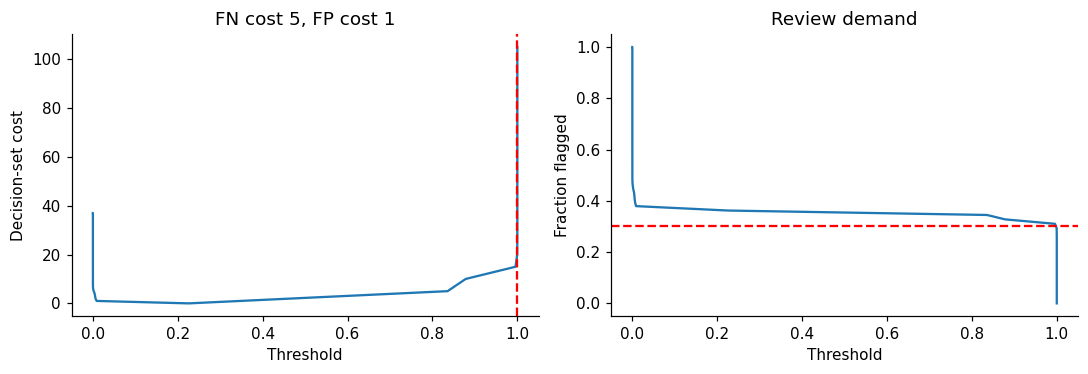

In [5]:

pd_dec=probabilities[selected]['decision'][1]
def outcome(y,p,threshold,cap=None):
    flagged=p>=threshold
    if cap is not None:
        eligible=np.flatnonzero(flagged); limit=int(np.floor(cap*len(y)))
        keep=eligible[np.argsort(-p[eligible],kind='stable')[:limit]]; flagged=np.zeros(len(y),dtype=bool); flagged[keep]=True
    return {'FN':int(np.sum((y==1)&~flagged)),'FP':int(np.sum((y==0)&flagged)),'reviewed':int(flagged.sum()),'n':len(y)}
def threshold_grid(cost,capacity):
    rows=[]
    for t in np.r_[0,np.unique(pd_dec),1.000001]:
        o=outcome(y[decision],pd_dec,t); rows.append({'threshold':float(t),**o,'cost':cost*o['FN']+o['FP'],'feasible':o['reviewed']<=int(np.floor(capacity*len(decision)))})
    frame=pd.DataFrame(rows); choice=frame[frame.feasible].sort_values(['cost','reviewed','threshold'],ascending=[True,True,False]).iloc[0]
    return frame,choice
grid,chosen=threshold_grid(5,.3); threshold=float(chosen.threshold); grid.to_csv(RUN/'threshold_curve.csv',index=False)
sensitivity=[]
for cost in [1,5,10]:
    for capacity in [.1,.3,.5]:
        _,c=threshold_grid(cost,capacity); sensitivity.append({'FN_cost':cost,'capacity':capacity,**c.to_dict()})
table('threshold_sensitivity',pd.DataFrame(sensitivity))
testp=probabilities[selected]['test'][1]; uncapped=outcome(y[test],testp,threshold); capped=outcome(y[test],testp,threshold,.3)
record={'model':selected,'threshold':threshold,'FN_cost':5,'FP_cost':1,'capacity':.3,'selection_partition':'decision','decision':chosen.to_dict(),'test_fixed_threshold':uncapped,'test_threshold_plus_cap':capped,'policy':'threshold then top floor(0.3*n) scores; ties stable row order; unreviewed positives count as false negatives'}
save_json('threshold_decision.json',record); print(json.dumps(record,indent=2))
fig,ax=plt.subplots(1,2,figsize=(10,3.5)); ax[0].plot(grid.threshold,grid.cost); ax[0].axvline(threshold,color='red',ls='--'); ax[0].set(xlabel='Threshold',ylabel='Decision-set cost',title='FN cost 5, FP cost 1')
ax[1].plot(grid.threshold,grid.reviewed/len(decision)); ax[1].axhline(.3,color='red',ls='--'); ax[1].set(xlabel='Threshold',ylabel='Fraction flagged',title='Review demand'); figure('cost_capacity')


## 06 · Error slices and claim boundary

Mean-radius quartile boundaries are frozen from training features. Error rates include denominators, because the held-out sample is small. These are morphology slices, not demographic fairness evidence. High discrimination on historical biopsy images does not establish safe clinical use, general population screening performance or capacity in a different institution. The threshold is an illustrative resource allocation exercise, and its small decision partition creates substantial policy uncertainty.

In [6]:

bounds=np.quantile(X.iloc[train].radius_mean,[.25,.5,.75]); slice_id=np.searchsorted(bounds,X.iloc[test].radius_mean)
flag=testp>=threshold; eligible=np.flatnonzero(flag); keep=eligible[np.argsort(-testp[eligible],kind='stable')[:int(.3*len(test))]]; flag[:]=False; flag[keep]=True
errors=pd.DataFrame({'row':test,'y':y[test],'p':testp,'review':flag,'radius_quartile':slice_id+1})
errors['type']=np.select([(errors.y==1)&~errors.review,(errors.y==0)&errors.review],['FN','FP'],default='correct')
errors.to_csv(RUN/'error_cases.csv',index=False)
slices=[]
for q,g in errors.groupby('radius_quartile'):
    npos=int((g.y==1).sum()); nneg=len(g)-npos
    slices.append({'radius_quartile':int(q),'n':len(g),'positives':npos,'negatives':nneg,'FN':int((g.type=='FN').sum()),'FP':int((g.type=='FP').sum()),'FN_rate':float((g.type=='FN').sum()/npos) if npos else None,'Brier':brier_score_loss(g.y,g.p)})
table('critical_slices',pd.DataFrame(slices)); display(errors[errors.type!='correct'])
m=metrics(y[test],testp); rawm=metrics(y[test],probabilities[selected]['test'][0]); facts={'selected':selected,'n':len(y),'test_n':len(test),'metrics':m,'raw_Brier':rawm['Brier'],'threshold':threshold,'test_policy':capped}
summary=f"""This study compares logistic regression, random forest, and histogram gradient boosting on {len(y)} records from the UCI Wisconsin Diagnostic Breast Cancer dataset. Stratified partitions separate training, sigmoid calibration, threshold decisions, and a final test of {len(test)} records. Each model receives three candidates and the same five training folds; development average precision selects {selected}. IDs are excluded, and all preprocessing is fitted within the relevant training partition.

For the selected calibrated model, test ROC AUC is {m['ROC_AUC']:.3f}, average precision is {m['AP']:.3f}, Brier score is {m['Brier']:.4f}, and five-bin expected calibration error is {m['ECE_5']:.4f}. Its uncalibrated Brier score is {rawm['Brier']:.4f}. Paired stratified bootstrap intervals retain identical sampled test rows across models and probability versions. A sharpened-probability counterexample leaves ranking unchanged while altering probability quality, showing why discrimination alone is insufficient.

A separate decision partition chooses threshold {threshold:.4f} under a hypothetical false-negative cost of five, false-positive cost of one, and thirty-percent review capacity. The threshold plus capacity cap reviews {capped['reviewed']} test cases, with {capped['FN']} false negatives and {capped['FP']} false positives. Cost and capacity sensitivity, calibration-bin counts, and training-defined radius slices are retained. These are teaching policies, not clinical recommendations. Small calibration, decision, and test samples limit precision, and the bootstrap conditions on fitted models and fixed class counts rather than accounting for training uncertainty or institutional shift."""

notes=f"""## Interpretation of this run

The strong simple baseline, {selected}, wins the development comparison. Its calibrated Brier score ({m['Brier']:.4f}) is higher than its raw score ({rawm['Brier']:.4f}); calibration did not improve this held-out probability loss. The calibrated policy is retained because it was specified before test evaluation. Replacing it after this result would require new evaluation data.

Sharpening leaves ROC AUC unchanged but changes Brier from {counter.iloc[0].Brier:.4f} to {counter.iloc[1].Brier:.4f} and log loss from {counter.iloc[0].LogLoss:.4f} to {counter.iloc[1].LogLoss:.4f}. Good ranking therefore does not certify trustworthy probabilities.

The decision-set threshold is high ({threshold:.6f}) and the final policy misses {capped['FN']} positives out of {int(y[test].sum())}, despite excellent ranking. The hypothetical review constraint is consequential, and small-sample threshold uncertainty is not captured by model-metric bootstrap intervals. A fixed threshold can also leave capacity unused; the predefined rule caps excess demand but does not force the batch to fill every review slot. Neither this example nor its costs justify a clinical workflow.
"""

(RUN/'DISCUSSION.md').write_text(notes)
display(Markdown(notes))



,radius_quartile,n,positives,negatives,FN,FP,FN_rate,Brier
0,1,19,1,18,0,0,0.0,0.000014
1,2,21,1,20,1,0,1.0,0.000050
2,3,25,10,15,6,0,0.6,0.085191
3,4,21,20,1,4,0,0.2,0.000217


,row,y,p,review,radius_quartile,type
1,29,1,0.942388,False,4,FN
2,141,1,0.995860,False,4,FN
3,255,1,0.063337,False,3,FN
8,172,1,0.994347,False,3,FN
18,182,1,0.999167,False,3,FN
22,514,1,0.105993,False,3,FN
54,283,1,0.971362,False,4,FN
55,330,1,0.968091,False,3,FN
70,186,1,0.998029,False,4,FN
74,99,1,0.459339,False,3,FN


## Interpretation of this run

The strong simple baseline, Logistic, wins the development comparison. Its calibrated Brier score (0.0248) is higher than its raw score (0.0209); calibration did not improve this held-out probability loss. The calibrated policy is retained because it was specified before test evaluation. Replacing it after this result would require new evaluation data.

Sharpening leaves ROC AUC unchanged but changes Brier from 0.0248 to 0.0278 and log loss from 0.0766 to 0.1268. Good ranking therefore does not certify trustworthy probabilities.

The decision-set threshold is high (0.999711) and the final policy misses 11 positives out of 32, despite excellent ranking. The hypothetical review constraint is consequential, and small-sample threshold uncertainty is not captured by model-metric bootstrap intervals. A fixed threshold can also leave capacity unused; the predefined rule caps excess demand but does not force the batch to fill every review slot. Neither this example nor its costs justify a clinical workflow.


## Completion and evidence

The following summary is computed from this run. OpenAI Codex assisted with the implementation, execution and report preparation. Automated checks are separate from the author's independent verification and reflection recorded at the end of this notebook.

In [7]:
assert 150 <= len(summary.split()) <= 300, len(summary.split())
(RUN/'ABSTRACT.md').write_text('# Abstract\n\n'+summary+'\n')
save_json('summary.json', facts)
save_json('completed.json', {'completed_utc':datetime.datetime.now(datetime.timezone.utc).isoformat(),'protocol_sha256':sha(BASE/'protocol.json'),'manifest_sha256':sha(BASE/'data/raw/manifest.json'),'summary_words':len(summary.split()),'analysis_source_sha256':sha(BASE/'analysis.py'),'notebook_code_sha256':notebook_code_hash(),'personal_verification':'Not asserted by automated execution'})
display(Markdown('## Results summary\n\n'+summary))
print('RESULT_DIR:', RUN.relative_to(BASE).as_posix())


## Results summary

This study compares logistic regression, random forest, and histogram gradient boosting on 569 records from the UCI Wisconsin Diagnostic Breast Cancer dataset. Stratified partitions separate training, sigmoid calibration, threshold decisions, and a final test of 86 records. Each model receives three candidates and the same five training folds; development average precision selects Logistic. IDs are excluded, and all preprocessing is fitted within the relevant training partition.

For the selected calibrated model, test ROC AUC is 0.999, average precision is 0.998, Brier score is 0.0248, and five-bin expected calibration error is 0.0318. Its uncalibrated Brier score is 0.0209. Paired stratified bootstrap intervals retain identical sampled test rows across models and probability versions. A sharpened-probability counterexample leaves ranking unchanged while altering probability quality, showing why discrimination alone is insufficient.

A separate decision partition chooses threshold 0.9997 under a hypothetical false-negative cost of five, false-positive cost of one, and thirty-percent review capacity. The threshold plus capacity cap reviews 21 test cases, with 11 false negatives and 0 false positives. Cost and capacity sensitivity, calibration-bin counts, and training-defined radius slices are retained. These are teaching policies, not clinical recommendations. Small calibration, decision, and test samples limit precision, and the bootstrap conditions on fitted models and fixed class counts rather than accounting for training uncertainty or institutional shift.

RESULT_DIR: results/20261010T104325122644Z


<div style="break-before: page"></div>

## Student independent verification and Reflection

I used an additional calculation of the Brier score using the four radius-based test groups.

The weighted calculation gave 0.02483312, consistent with the Notebook's calibrated Logistic Brier score of 0.024833.

I also checked the reported review policy figures. The test set contained 86 records, including 32 positive cases. The policy reviewed 21 cases and missed 11 positives. This gives a false-negative fraction of 11/32, or 34.375%.

The review count is within the 30% capacity limit. These checks confirm the consistency of the saved summary tables, but they do not independently validate every predicted probability.

The result I found most important is that a model can have a very high ROC AUC and still make costly mistakes under a particular decision rule.

I also noticed that calibration reduced ECE but increased the Brier score. Therefore, calibration should not automatically be described as an improvement in every metric.

I agree with separating model training, calibration, threshold selection and testing. However, the cost assumptions and selected threshold are only part of a teaching experiment, not a recommendation for real clinical decisions.
